# Bayesian Robust Trading Agent Walkthrough

This notebook is a guided tour of what this repository is trying to do. The short version is:

1. Build market datasets from price and feature files.
2. Analyze whether the time series look stationary, trending, mean-reverting, or noisy.
3. Train a trading agent that chooses between short, neutral/close, and long positions.
4. Add robustness by exposing the agent to adversarial and synthetic market observations.
5. Add a learned quantile-belief state so the DQN can condition decisions on an estimated market regime.

The repo does not currently include a clean end-to-end notebook for the RL agent, and this checkout may not include the full `datasets/` folder. This notebook is written to be readable first and executable second: when real parquet data is present it uses it; otherwise it creates a small synthetic price series so every concept still has something concrete to show.

## 1. Repository Map

The project has a few separate layers:

- `tools/` and `configs/downloader/`: download price, news, sentiment, and economic data.
- `module/processor/`: turn raw price data into technical features such as returns, moving averages, volatility, rolling quantiles, and volume indicators.
- `data_analysis/`: inspect datasets statistically and visually. Your open file, `data_analysis/quantitative_analysis.py`, belongs here.
- `generator/GRT_GAN/` and `module/augmentation/`: create synthetic or augmented market data.
- `downstream_tasks/rl/trading/dqn/`: train and evaluate the robust DQN trading agent.

The agent is called "Bayesian" in the broader project idea because it carries a learned belief about where the current price sits relative to predicted future quantiles. In code this is named `use_quantile_belief` and implemented by the `QuantileBelief` network in `downstream_tasks/rl/trading/dqn/qnet.py`.

In [4]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))
print("Repository root:", ROOT)

interesting_paths = [
    "data_analysis/quantitative_analysis.py",
    "module/processor/processor.py",
    "downstream_tasks/rl/trading/dqn/train.py",
    "downstream_tasks/rl/trading/dqn/environment.py",
    "downstream_tasks/rl/trading/dqn/qnet.py",
    "downstream_tasks/rl/trading/dqn/configs/SPY.py",
    "generator/GRT_GAN/models/API.py",
]

for rel_path in interesting_paths:
    path = ROOT / rel_path
    print(f"{'FOUND' if path.exists() else 'MISSING'}  {rel_path}")

Repository root: /Users/ethan/Documents/workspace/Bayesian-Robust-Financial-Trading-with-Adversarial-Synthetic-Market-Data
FOUND  data_analysis/quantitative_analysis.py
FOUND  module/processor/processor.py
FOUND  downstream_tasks/rl/trading/dqn/train.py
FOUND  downstream_tasks/rl/trading/dqn/environment.py
FOUND  downstream_tasks/rl/trading/dqn/qnet.py
FOUND  downstream_tasks/rl/trading/dqn/configs/SPY.py
FOUND  generator/GRT_GAN/models/API.py


## 2. What `quantitative_analysis.py` Is Doing

The active script, `data_analysis/quantitative_analysis.py`, walks through every `.parquet` and `.csv` file under a dataset directory and calculates time-series diagnostics for target columns such as `ret1`.

Those diagnostics answer different questions:

- **KPSS test**: asks whether the series is stationary. A larger statistic can mean the series has changing level/trend behavior.
- **Hurst exponent**: estimates memory in the series. Rough guide: below `0.5` suggests mean reversion, around `0.5` suggests random-walk-like behavior, above `0.5` suggests persistence/trending.
- **Variance ratio**: compares multi-period variance with one-period variance. This is another way to check random-walk behavior.
- **Autocorrelation**: checks whether recent values are correlated with lagged values.

This matters because the trading agent is being trained on market series. If returns are unstable, heavily autocorrelated, or regime-dependent, a plain DQN may overfit. The robust/adversarial parts of the repo are meant to reduce that fragility.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
sns.set_theme(style="whitegrid")

candidate_data_dirs = [
    ROOT / "datasets/processd_day_future_etfs/features",
    ROOT / "datasets/processd_day_dj30/features",
    ROOT / "datasets",
]

data_files = []
for data_dir in candidate_data_dirs:
    if data_dir.exists():
        data_files.extend(sorted(data_dir.rglob("*.parquet")))
        data_files.extend(sorted(data_dir.rglob("*.csv")))

print(f"Found {len(data_files)} local data files.")
for path in data_files[:10]:
    print(path.relative_to(ROOT))

Found 0 local data files.


## 3. Load One Market Series

The real training pipeline expects processed parquet files with columns like `timestamp`, OHLCV prices, engineered features, and labels such as `ret1` or `mov1`.

If the data files are missing locally, the next cell creates a small synthetic daily series. That synthetic fallback is not a substitute for training, but it lets us inspect the same ideas: price, return, rolling trend, rolling volatility, and quantile bands.

In [6]:
def make_synthetic_market_data(n=700):
    dates = pd.date_range("2020-01-01", periods=n, freq="B")
    regime = np.where(np.arange(n) < n * 0.45, 0.0004, -0.0001)
    shocks = np.random.normal(loc=regime, scale=0.018, size=n)
    close = 100 * np.exp(np.cumsum(shocks))
    open_ = close * (1 + np.random.normal(0, 0.002, size=n))
    high = np.maximum(open_, close) * (1 + np.abs(np.random.normal(0, 0.006, size=n)))
    low = np.minimum(open_, close) * (1 - np.abs(np.random.normal(0, 0.006, size=n)))
    volume = np.random.lognormal(mean=13.2, sigma=0.25, size=n)

    df = pd.DataFrame({
        "timestamp": dates,
        "open": open_,
        "high": high,
        "low": low,
        "close": close,
        "adj_close": close,
        "volume": volume,
    })
    df["ret1"] = df["close"].pct_change().shift(-1)
    df["mov1"] = (df["ret1"] > 0).astype(int)
    return df.dropna().reset_index(drop=True)

if data_files:
    sample_path = data_files[0]
    if sample_path.suffix == ".parquet":
        df = pd.read_parquet(sample_path)
    else:
        df = pd.read_csv(sample_path)
    print("Loaded real file:", sample_path.relative_to(ROOT))
else:
    df = make_synthetic_market_data()
    print("No local dataset found, using synthetic data for the walkthrough.")

if "timestamp" in df.columns:
    df["timestamp"] = pd.to_datetime(df["timestamp"])
elif "date" in df.columns:
    df = df.rename(columns={"date": "timestamp"})
    df["timestamp"] = pd.to_datetime(df["timestamp"])

print(df.shape)
df.head()

No local dataset found, using synthetic data for the walkthrough.
(699, 9)


,timestamp,open,high,low,close,adj_close,volume,ret1,mov1
0,2020-01-01,100.832936,101.572503,100.605209,100.938462,100.938462,5.657789e+05,-0.002087,0
1,2020-01-02,100.939175,101.264190,100.182675,100.727846,100.727846,1.059448e+06,0.012131,1
2,2020-01-03,101.806199,102.675108,101.274976,101.949814,101.949814,5.897476e+05,0.028205,1
3,2020-01-06,104.530021,105.277493,103.824171,104.825306,104.825306,4.204103e+05,-0.003807,0
4,2020-01-07,104.101079,105.050265,103.358164,104.426185,104.426185,5.276212e+05,-0.003807,0


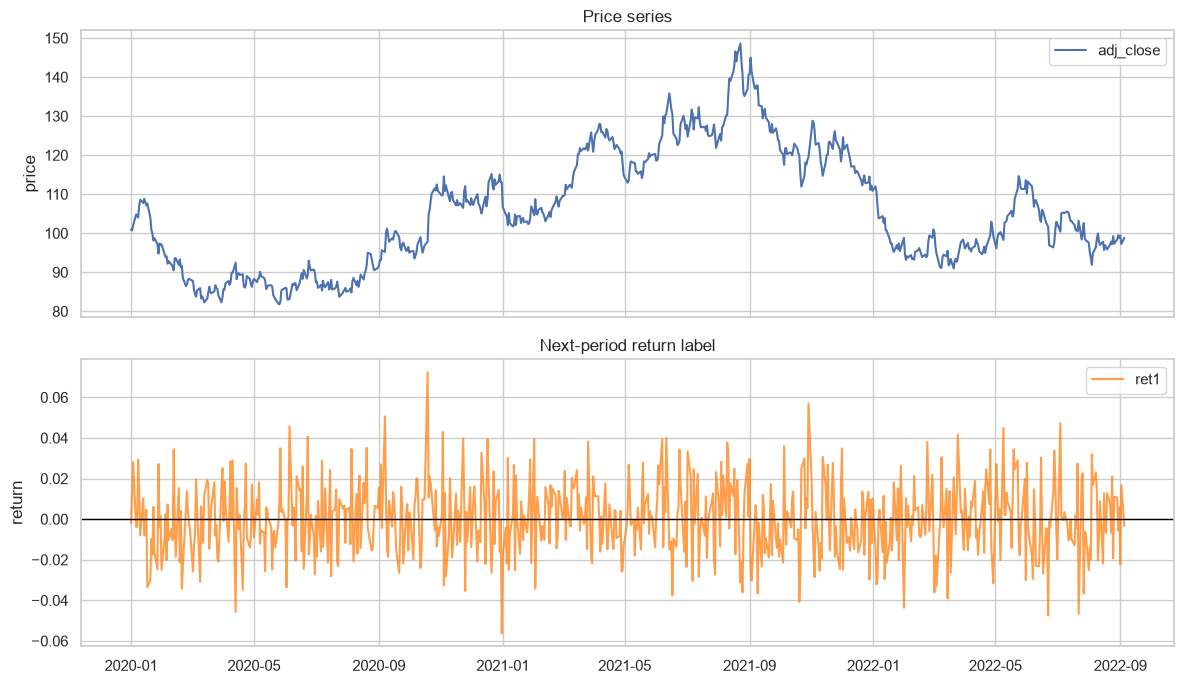

In [7]:
price_col = "adj_close" if "adj_close" in df.columns else "close"
if "ret1" not in df.columns:
    df["ret1"] = df[price_col].pct_change().shift(-1)

plot_df = df.dropna(subset=[price_col, "ret1"]).copy()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
x = plot_df["timestamp"] if "timestamp" in plot_df.columns else plot_df.index
axes[0].plot(x, plot_df[price_col], label=price_col)
axes[0].set_title("Price series")
axes[0].set_ylabel("price")
axes[0].legend()

axes[1].plot(x, plot_df["ret1"], color="tab:orange", alpha=0.75, label="ret1")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Next-period return label")
axes[1].set_ylabel("return")
axes[1].legend()
plt.tight_layout()

## 4. Recreate the Quantitative Diagnostics

The next cell mirrors the intent of `data_analysis/quantitative_analysis.py`, but keeps it compact and notebook-friendly. We use the return column because returns are what the trading task ultimately cares about: the agent is rewarded when portfolio value rises from one step to the next.

Interpretation should be cautious. These tests are useful signals, not trading rules. A high autocorrelation or Hurst exponent does not automatically mean "buy" or "sell"; it means the data may contain dependence that a model might exploit or overfit.

In [8]:
import statsmodels.tsa.stattools as ts

def kpss_test(series):
    statistic, p_value, lags, critical_values = ts.kpss(series, regression="c", nlags="auto")
    return {
        "statistic": statistic,
        "p_value": p_value,
        "lags": lags,
        "critical_values": critical_values,
    }

def hurst_exponent(series):
    series = pd.Series(series).dropna().reset_index(drop=True)
    max_lag = min(100, len(series) // 2)
    lags = range(2, max_lag)
    tau = [np.sqrt(np.std(series[lag:].reset_index(drop=True) - series[:-lag].reset_index(drop=True))) for lag in lags]
    poly = np.polyfit(np.log(list(lags)), np.log(tau), 1)
    return poly[0] * 2.0

def variance_ratio(series, lag=2):
    series = pd.Series(series).dropna().reset_index(drop=True)
    diffs = np.diff(series)
    var_diff = np.var(diffs)
    if var_diff == 0:
        return np.nan
    cumulative_diffs = series[lag:].reset_index(drop=True) - series[:-lag].reset_index(drop=True)
    return (np.var(cumulative_diffs) / lag) / var_diff

returns = plot_df["ret1"].dropna()
diagnostics = {
    "kpss": kpss_test(returns),
    "hurst_exponent": hurst_exponent(returns),
    "variance_ratio_lag_2": variance_ratio(returns, lag=2),
    "autocorrelation_lag_1": returns.autocorr(lag=1),
}
diagnostics

/var/folders/fd/q49tbb0x7mn28q58hxpnhm7r0000gn/T/ipykernel_69640/201479960.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  statistic, p_value, lags, critical_values = ts.kpss(series, regression="c", nlags="auto")


{'kpss': {'statistic': np.float64(0.11282877539117284),
  'p_value': np.float64(0.1),
  'lags': 9,
  'critical_values': {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}},
 'hurst_exponent': np.float64(-0.0018442808158786919),
 'variance_ratio_lag_2': np.float64(0.500091431672928),
 'autocorrelation_lag_1': np.float64(-0.015340703365373805)}

## 5. Feature Engineering: What the Model Sees

The DQN does not receive only raw prices. The config files list about 150 market features plus temporal features such as day, weekday, and month.

A few important examples:

- `ma_5`, `ma_20`, `ma_60`: rolling moving averages.
- `std_5`, `std_20`, `std_60`: rolling volatility.
- `qtlu_*` and `qtld_*`: rolling upper/lower quantile ratios.
- `ret1`: next-period return label.
- `mov1`: next-period direction label.

The quantile features are separate from the learned `QuantileBelief` network. The features summarize historical windows; the belief network learns to predict future quantile levels and turns them into a discrete regime-like input for the Q-network.

In [9]:
feature_demo = plot_df[["timestamp", price_col, "ret1"]].copy() if "timestamp" in plot_df.columns else plot_df[[price_col, "ret1"]].copy()
for window in [5, 20, 60]:
    feature_demo[f"ma_{window}"] = feature_demo[price_col].rolling(window).mean()
    feature_demo[f"std_{window}"] = feature_demo[price_col].rolling(window).std()
    feature_demo[f"qtlu_{window}"] = feature_demo[price_col].rolling(window).quantile(0.8) / feature_demo[price_col]
    feature_demo[f"qtld_{window}"] = feature_demo[price_col].rolling(window).quantile(0.2) / feature_demo[price_col]

feature_demo.tail()

,timestamp,adj_close,ret1,ma_5,std_5,qtlu_5,qtld_5,ma_20,std_20,qtlu_20,qtld_20,ma_60,std_60,qtlu_60,qtld_60
694,2022-08-30,99.429441,-0.005656,98.308521,1.044189,0.998399,0.978432,96.984802,1.937422,0.990037,0.963618,100.472764,3.868486,1.049670,0.975338
695,2022-08-31,98.867089,0.005787,98.643764,0.845907,1.004078,0.992933,97.239859,1.823811,0.998327,0.974217,100.341258,3.784422,1.048394,0.980886
696,2022-09-01,99.439241,-0.022366,98.685526,0.886302,0.999921,0.987220,97.616773,1.389655,0.994977,0.970304,100.192908,3.637141,1.038534,0.975242
697,2022-09-02,97.215170,0.016670,98.666875,0.922758,1.022797,1.009614,97.735715,1.232008,1.017740,0.996150,100.005287,3.490186,1.061147,0.997554
698,2022-09-05,98.835737,-0.003422,98.757336,0.910108,1.006027,0.996721,97.855630,1.215600,1.001052,0.981197,99.886345,3.403929,1.043048,0.981197


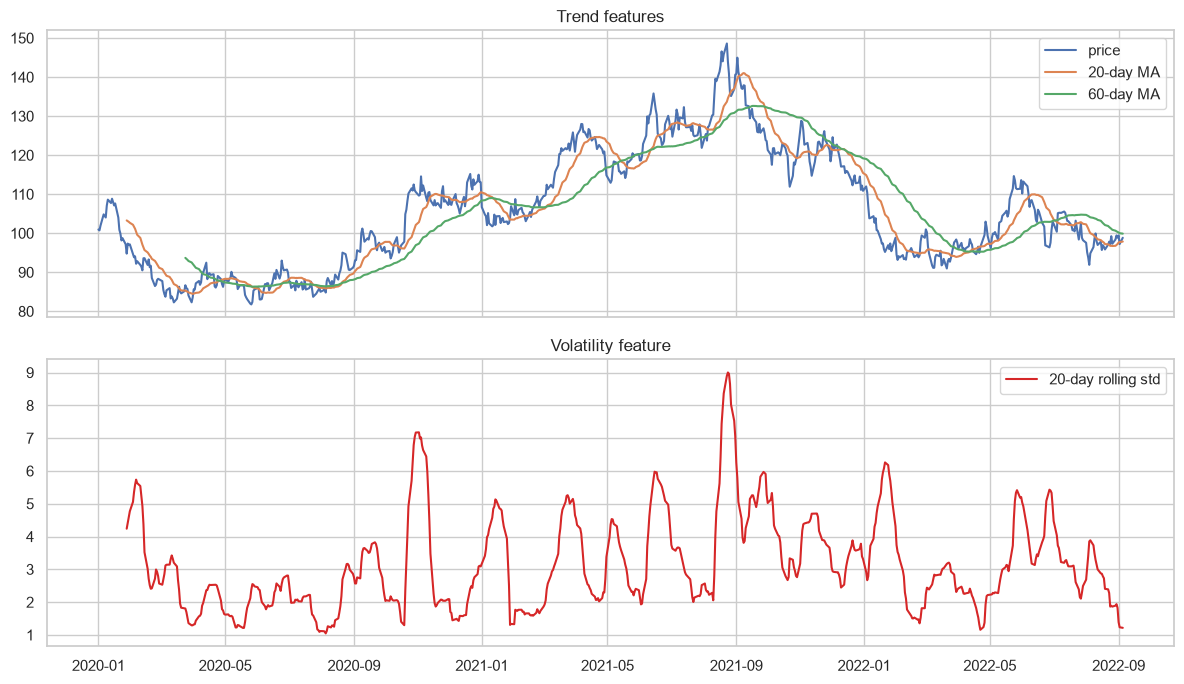

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
x = feature_demo["timestamp"] if "timestamp" in feature_demo.columns else feature_demo.index
axes[0].plot(x, feature_demo[price_col], label="price")
axes[0].plot(x, feature_demo["ma_20"], label="20-day MA")
axes[0].plot(x, feature_demo["ma_60"], label="60-day MA")
axes[0].set_title("Trend features")
axes[0].legend()

axes[1].plot(x, feature_demo["std_20"], color="tab:red", label="20-day rolling std")
axes[1].set_title("Volatility feature")
axes[1].legend()
plt.tight_layout()

## 6. Trading Environment: Turning Data into Actions and Rewards

The RL code uses `EnvironmentRET` in `downstream_tasks/rl/trading/dqn/environment.py`.

At each step the environment gives the agent a rolling window of features. With the default configs, that window is `30` days by `153` features. The agent chooses one of three discrete actions:

- `0`: short / sell-side exposure.
- `1`: close / neutral.
- `2`: long / buy-side exposure.

The environment updates cash, position, transaction cost, portfolio value, and reward. The reward is the fractional change in portfolio value for the step:

`reward = (post_value - pre_value) / pre_value`

The simplified simulator below mirrors that idea without requiring the full project dataset class.

In [11]:
class TinyTradingEnvironment:
    def __init__(self, prices, initial_amount=10_000, transaction_cost_pct=1e-3):
        self.prices = np.asarray(prices, dtype=float)
        self.initial_amount = initial_amount
        self.transaction_cost_pct = transaction_cost_pct
        self.actions = ["short", "close", "long"]
        self.reset()

    def reset(self):
        self.t = 0
        self.cash = float(self.initial_amount)
        self.position = 0.0
        self.previous_exposure = 0
        self.value = float(self.initial_amount)
        return self._info("reset")

    def current_value(self, price):
        return self.cash + self.position * price

    def step(self, action_id):
        exposure = action_id - 1  # maps 0,1,2 to -1,0,1
        price = self.prices[self.t]
        pre_value = self.value

        target_stock_value = exposure * pre_value
        target_position = target_stock_value / price
        trade_size = target_position - self.position
        cost = abs(trade_size * price) * self.transaction_cost_pct

        self.position = target_position
        self.cash = pre_value - self.position * price - cost
        self.value = self.current_value(price)

        self.t += 1
        next_price = self.prices[min(self.t, len(self.prices) - 1)]
        self.value = self.current_value(next_price)
        reward = (self.value - pre_value) / pre_value
        done = self.t >= len(self.prices) - 1
        return reward, done, self._info(self.actions[action_id])

    def _info(self, action):
        return {
            "t": self.t,
            "price": self.prices[min(self.t, len(self.prices) - 1)],
            "cash": self.cash,
            "position": self.position,
            "value": self.value,
            "action": action,
        }

prices = plot_df[price_col].dropna().values[:120]
env = TinyTradingEnvironment(prices)
records = [env.reset()]

# Toy policy: long when price is above the 20-day average, otherwise neutral.
for t in range(20, len(prices) - 1):
    rolling_mean = prices[t-20:t].mean()
    action_id = 2 if prices[t] > rolling_mean else 1
    reward, done, info = env.step(action_id)
    info["reward"] = reward
    records.append(info)
    if done:
        break

pd.DataFrame(records).head()

,t,price,cash,position,value,action,reward
0,0,100.938462,10000.0,0.0,10000.0,reset,NaN
1,1,100.727846,10000.0,0.0,10000.0,close,0.0
2,2,101.949814,10000.0,0.0,10000.0,close,0.0
3,3,104.825306,10000.0,0.0,10000.0,close,0.0
4,4,104.426185,10000.0,0.0,10000.0,close,0.0


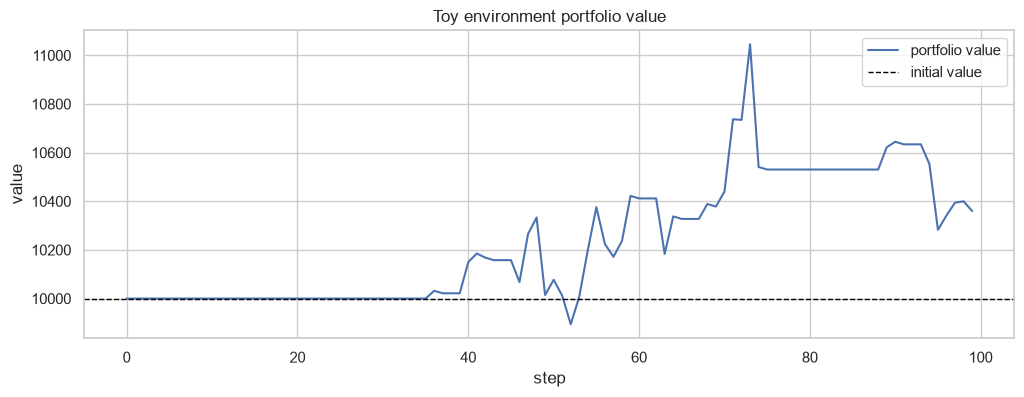

In [12]:
record_df = pd.DataFrame(records)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(record_df["t"], record_df["value"], label="portfolio value")
ax.axhline(env.initial_amount, color="black", linewidth=1, linestyle="--", label="initial value")
ax.set_title("Toy environment portfolio value")
ax.set_xlabel("step")
ax.set_ylabel("value")
ax.legend()

## 7. Quantile Belief: The Bayesian-Like State

The robust DQN can optionally use `QuantileBelief`. This network takes the recent observation window, predicts several quantile levels, and then the training code asks: which predicted quantile is closest to the current price-like feature?

In the training script this is done by `get_quantile_belief`:

1. Run the quantile belief network on all but the latest row of the observation window.
2. Take the final predicted vector of quantile heads, such as `[0.05, 0.25, 0.50, 0.75, 0.95]`.
3. Compare those predictions with the current price feature.
4. Return the index of the closest quantile.
5. Add an embedding of that index into the Q-network latent state.

That final index is the belief state. It is not a full probabilistic Bayesian posterior, but it plays a similar practical role: the policy is conditioned on an inferred market regime rather than only raw features.

In [12]:
quantile_heads = [0.05, 0.25, 0.50, 0.75, 0.95]
window = 60

belief_demo = feature_demo[[price_col]].dropna().copy()
for q in quantile_heads:
    belief_demo[f"q_{q:.2f}"] = belief_demo[price_col].rolling(window).quantile(q)

quantile_cols = [f"q_{q:.2f}" for q in quantile_heads]
belief_demo = belief_demo.dropna().copy()
differences = belief_demo[quantile_cols].sub(belief_demo[price_col], axis=0).abs()
belief_demo["belief_bucket"] = differences.values.argmin(axis=1)
belief_demo[[price_col] + quantile_cols + ["belief_bucket"]].tail()

,adj_close,q_0.05,q_0.25,q_0.50,q_0.75,q_0.95,belief_bucket
694,99.429441,95.084431,97.279038,100.355684,103.162690,106.050437,2
695,98.867089,95.084431,97.279038,100.136079,103.094001,105.974273,2
696,99.439241,95.084431,97.279038,99.689754,102.956220,105.575264,2
697,97.215170,95.084431,97.209095,99.434341,102.893546,105.510763,1
698,98.835737,95.084431,97.209095,99.329936,102.732828,105.281846,2


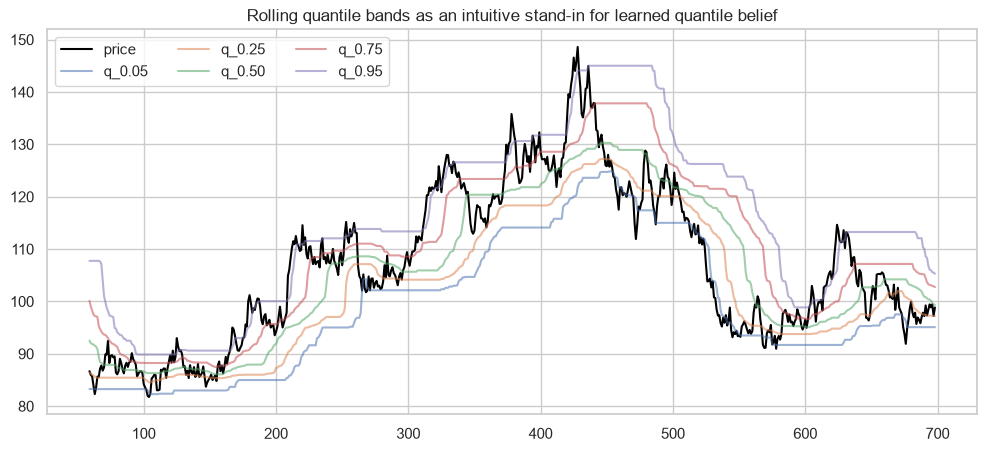

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
x = belief_demo.index
ax.plot(x, belief_demo[price_col], color="black", linewidth=1.5, label="price")
for col in quantile_cols:
    ax.plot(x, belief_demo[col], alpha=0.55, label=col)
ax.set_title("Rolling quantile bands as an intuitive stand-in for learned quantile belief")
ax.legend(ncol=3)

## 8. Q-Network: From Observation Window to Action Values

The actual DQN policy is in `downstream_tasks/rl/trading/dqn/qnet.py`.

Conceptually, the Q-network receives a tensor like:

`batch_size x timestamps x num_features`

and returns one score per action:

`batch_size x 3`

The selected action is the index with the largest Q-value. When quantile belief is enabled, the Q-network embeds the belief bucket and adds it to the latent representation before producing Q-values.

The full class depends on project dependencies such as PyTorch, `timm`, and `einops`. The next cell tries to instantiate it if dependencies are available; otherwise it prints a friendly explanation instead of failing the notebook.

In [24]:
import torch
print(torch.__version__)

ModuleNotFoundError: No module named 'torch'

In [15]:
try:
    import torch
    from downstream_tasks.rl.trading.dqn.qnet import QNet

    model = QNet(
        input_dim=153,
        timestamps=30,
        embed_dim=64,
        depth=1,
        output_dim=3,
        temporals_name=["day", "weekday", "month"],
        use_quantile_belief=True,
        quantile_heads_num=5,
        device=torch.device("cpu"),
    )
    fake_observation = torch.randn(4, 30, 153)
    fake_belief = torch.tensor([0, 1, 2, 3, 4])[:4]
    q_values = model(fake_observation, fake_belief)
    print("Q-values shape:", tuple(q_values.shape))
    print(q_values.detach())
except Exception as exc:
    print("Could not instantiate the project QNet in this environment.")
    print("This is usually due to missing optional ML dependencies or local dataset setup.")
    print(type(exc).__name__ + ":", exc)

Could not instantiate the project QNet in this environment.
This is usually due to missing optional ML dependencies or local dataset setup.
ModuleNotFoundError: No module named 'torch'


## 9. Robustness: Adversarial and Synthetic Observations

The central robustness idea lives in `data_augmentation_function` inside `downstream_tasks/rl/trading/dqn/train.py`.

The config parameter `augmentation_method` can choose:

- `random`: add random noise to observations.
- `min_q`: use gradients to perturb observations in the direction that lowers the chosen Q-value.
- `adv_agent`: train a second continuous actor to produce adversarial observation noise.
- `generator_noise`: call the GRT-GAN generator to create synthetic market observations.
- `generator_adv_agent`: combine generated market data with adversarial noise.

Why this helps: a trading model can learn brittle patterns that work only in the historical sample. Perturbing the input distribution forces the policy to survive nearby or synthetic market paths.

,original_return,random_augmented_return
count,300.000000,300.000000
mean,0.000377,0.000475
std,0.017766,0.021721
min,-0.056296,-0.056414
25%,-0.012040,-0.013658
50%,0.001335,0.001838
75%,0.011748,0.014641
max,0.072239,0.076760


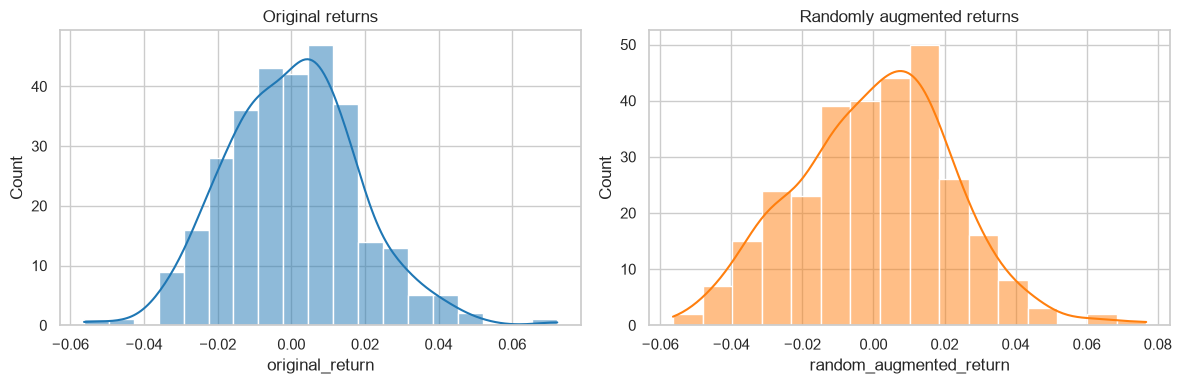

In [15]:
base_returns = returns.iloc[:300].reset_index(drop=True)
random_noise = np.random.normal(0, base_returns.std() * 0.6, size=len(base_returns))
augmented_returns = base_returns + random_noise

comparison = pd.DataFrame({
    "original_return": base_returns,
    "random_augmented_return": augmented_returns,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(comparison["original_return"], ax=axes[0], kde=True, color="tab:blue")
axes[0].set_title("Original returns")
sns.histplot(comparison["random_augmented_return"], ax=axes[1], kde=True, color="tab:orange")
axes[1].set_title("Randomly augmented returns")
plt.tight_layout()

comparison.describe()

## 10. How the Full Training Script Fits Together

The full training script does the following:

1. Load a config, for example `downstream_tasks/rl/trading/dqn/configs/SPY.py`.
2. Load one ticker's processed parquet file.
3. Build train and validation environments.
4. Create the DQN agent, target network, optional NFSP network, and optional quantile-belief network.
5. Step through the environment using epsilon-greedy exploration.
6. Optionally augment observations before selecting actions.
7. Store transitions in a replay buffer.
8. Train the quantile-belief network with quantile loss.
9. Train the Q-network with TD targets.
10. Periodically validate, save checkpoints, and write trading records.

A normal run looks like this from the repo root:

```bash
python downstream_tasks/rl/trading/dqn/train.py --config downstream_tasks/rl/trading/dqn/configs/SPY.py
```

A faster smoke-test run can override the config values:

```bash
python downstream_tasks/rl/trading/dqn/train.py \
  --config downstream_tasks/rl/trading/dqn/configs/SPY.py \
  --cfg-options total_timesteps=2000 learning_starts=100 batch_size=32 check_steps=500
```

That still requires the expected processed datasets to exist locally.

In [16]:
config_path = ROOT / "downstream_tasks/rl/trading/dqn/configs/SPY.py"
print(config_path)

if config_path.exists():
    text = config_path.read_text()
    for key in [
        "select_stock",
        "train_start_date",
        "valid_start_date",
        "test_start_date",
        "total_timesteps",
        "use_data_augmentation",
        "augmentation_method",
        "use_nfsp",
        "use_quantile_belief",
        "quantile_heads",
    ]:
        for line in text.splitlines():
            if line.startswith(key):
                print(line)
                break

/Users/ethan/Documents/workspace/Bayesian-Robust-Financial-Trading-with-Adversarial-Synthetic-Market-Data/downstream_tasks/rl/trading/dqn/configs/SPY.py
select_stock = "SPY"
train_start_date = "2000-01-01"
valid_start_date = "2018-01-01"
test_start_date = "2021-01-01"
total_timesteps = int(1e6)  # int(2e5)
use_data_augmentation = True
augmentation_method = 'generator_adv_agent'   # ['random', 'min_q', 'adv_agent', 'generator_noise', 'generator_adv_agent']
use_nfsp = True
use_quantile_belief = True
quantile_heads = [0.05, 0.25, 0.5, 0.75, 0.95]


## 11. What to Look at Next

If you want to understand the project by reading code, use this order:

1. `data_analysis/quantitative_analysis.py` to understand the dataset diagnostics.
2. `module/processor/processor.py` to understand the technical indicators.
3. `downstream_tasks/rl/trading/dqn/environment.py` to understand portfolio mechanics and rewards.
4. `downstream_tasks/rl/trading/dqn/qnet.py` to understand Q-values and quantile belief.
5. `downstream_tasks/rl/trading/dqn/train.py` to understand replay-buffer training, augmentation, NFSP, validation, and checkpointing.
6. `generator/GRT_GAN/models/API.py` to understand how synthetic observations enter the robust training path.

The most important mental model is this: the repo is not just forecasting prices. It is building a trading policy, then deliberately making the training distribution harder through synthetic and adversarial market states so the policy is less fragile.